# Perbandingan Metode Seleksi Fitur: Information Gain vs Chi-Square vs RFE

Dataset: `Dataset_Latihan_Preprocessing.csv`
Target: `churn_3bln` (1 = churn, 0 = tidak churn)

Notebook ini menjalankan tiga metode seleksi fitur pada data yang sama, lalu membandingkan fitur yang dipilih dan performa model yang dihasilkan.

| | Information Gain | Chi-Square | RFE |
|---|---|---|---|
| Jenis | Filter | Filter | Wrapper |
| Cara menilai fitur | Satu per satu | Satu per satu | Bersamaan dalam satu model |
| Dasar perhitungan | Penurunan entropi | Uji hipotesis (tabel kontingensi) | Koefisien model (Logistic Regression) |
| Butuh model? | Tidak | Tidak | Ya |
| Butuh scaling/encoding? | Tidak | Tidak | Ya |
| Kecepatan | Cepat | Cepat | Lebih lambat (model dilatih berulang) |

Langkah-langkah:
1. Load data
2. Preprocessing untuk RFE
3. Jalankan ketiga metode
4. Tabel perbandingan peringkat
5. Visualisasi peringkat
6. Benchmark performa model
7. Simpan tabel perbandingan
8. Kesimpulan

### 1. Load Library dan Dataset

In [1]:
import pandas as pd
import numpy as np
import math
from collections import Counter
from scipy.stats import chi2_contingency
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
import matplotlib.pyplot as plt

df = pd.read_csv('Dataset_Latihan_Preprocessing.csv')
proporsi = df['churn_3bln'].value_counts(normalize=True) * 100
print(f"Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom.")
print(f"Target: 0 = tidak churn ({proporsi[0]:.1f}%), 1 = churn ({proporsi[1]:.1f}%)")
df.head()

Dataset berhasil dimuat: 1000 baris, 22 kolom.
Target: 0 = tidak churn (75.8%), 1 = churn (24.2%)


,id_pelanggan,usia_tahun,kota,kanal_akuisisi,tingkat_member,metode_pembayaran,langganan_newsletter,lama_member_bulan,jumlah_transaksi_6bln,rata_nilai_transaksi_rp,...,jumlah_keluhan_6bln,skor_kepuasan,persen_diskon_rata,jumlah_kunjungan_30hari,pengeluaran_bulanan_rp,kode_acak,warna_favorit,negara,kolom_hampir_kosong,churn_3bln
0,PLG0001,34.0,Jakarta,Iklan,Silver,Transfer Bank,Ya,33.0,7.0,280000.0,...,0.0,8.6,29.1,5.0,3380000.0,4262,Biru,Indonesia,NaN,0
1,PLG0002,43.0,Yogyakarta,Marketplace,Gold,E-Wallet,Tidak,15.0,11.0,226000.0,...,NaN,7.6,20.5,14.0,3260000.0,8377,Kuning,Indonesia,NaN,0
2,PLG0003,27.0,Jakarta,Iklan,Bronze,Kartu Kredit,Ya,13.0,9.0,431000.0,...,0.0,10.0,2.1,11.0,5070000.0,7000,Kuning,Indonesia,A,0
3,PLG0004,57.0,Jakarta,Referral,Platinum,COD,Ya,6.0,11.0,324000.0,...,0.0,NaN,29.8,NaN,2740000.0,7210,Kuning,Indonesia,NaN,0
4,PLG0005,27.0,Surabaya,Organik,Silver,Transfer Bank,Tidak,28.0,6.0,NaN,...,0.0,NaN,13.9,5.0,2150000.0,3037,Hijau,Indonesia,NaN,0


**Penjelasan:**

Dataset sama dengan notebook sebelumnya: 1000 baris, 22 kolom, dan target tidak seimbang (75,8% tidak churn, 24,2% churn). Karena kelasnya tidak seimbang, akurasi saja kurang cukup untuk menilai model. Di benchmark nanti dipakai juga ROC-AUC dan F1-Score.

### 2. Preprocessing untuk RFE

Information Gain dan Chi-Square dihitung langsung dari data mentah (`df`), dengan cara yang sama seperti di notebook masing-masing. Preprocessing di bawah ini hanya untuk RFE dan benchmark model, karena Logistic Regression butuh data yang semuanya angka, tanpa nilai kosong, dan berskala sama:
- `id_pelanggan` dibuang.
- Nilai kosong: numerik diisi median, kategorikal diisi `'Missing'`.
- Kategorikal di-encode dengan `OrdinalEncoder`.
- Semua fitur distandarisasi dengan `StandardScaler`.

In [2]:
df_clean = df.drop(columns=['id_pelanggan']).copy()

cat_cols = ['kota', 'kanal_akuisisi', 'tingkat_member', 'metode_pembayaran',
            'langganan_newsletter', 'warna_favorit', 'negara', 'kolom_hampir_kosong']
num_cols = [c for c in df_clean.columns if c not in cat_cols and c != 'churn_3bln']

for c in cat_cols:
    df_clean[c] = OrdinalEncoder().fit_transform(df_clean[[c]].fillna('Missing').astype(str)).ravel()
for c in num_cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

X = df_clean.drop(columns=['churn_3bln'])
y = df_clean['churn_3bln']
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

print(f"Fitur numerik     : {len(num_cols)}")
print(f"Fitur kategorikal : {len(cat_cols)}")
print(f"Ukuran X_scaled   : {X_scaled.shape}")
print(f"Sisa nilai kosong : {X_scaled.isnull().sum().sum()}")

Fitur numerik     : 12
Fitur kategorikal : 8
Ukuran X_scaled   : (1000, 20)
Sisa nilai kosong : 0


**Penjelasan:**

Setelah preprocessing ada 20 fitur (12 numerik + 8 kategorikal) untuk 1000 baris, dan tidak ada nilai kosong lagi. Data inilah yang dipakai RFE dan benchmark model. Ketiga metode menilai 20 fitur yang sama, jadi perbandingannya adil.

### 3. Jalankan Ketiga Metode

Aturan tipe fitur sama dengan notebook IG dan Chi-Square: kolom angka dengan lebih dari 10 nilai unik dianggap numerik kontinu, sisanya kategorikal. Jadi `jumlah_keluhan_6bln` (nilainya hanya 0-4) dihitung sebagai kategorikal.

- **Information Gain**: fitur numerik pakai *best binary split* (nilai kosong diabaikan), fitur kategorikal pakai entropi bersyarat (nilai kosong jadi kategori `'(Missing)'`).
- **Chi-Square**: fitur numerik dibagi 4 kuantil (`pd.qcut`), nilai kosong jadi kategori `'(Missing)'`.
- **RFE**: Logistic Regression, pilih 6 fitur, buang 1 fitur per iterasi.

In [3]:
# Aturan tipe fitur sama dengan notebook IG dan Chi-Square:
# kolom angka dengan > 10 nilai unik dianggap numerik kontinu, sisanya kategorikal
def is_numerik_kontinu(series, batas_unik=10):
    try:
        nilai = series.dropna().astype(float)
    except (ValueError, TypeError):
        return False
    return nilai.nunique() > batas_unik

fitur_kontinu = [c for c in X.columns if is_numerik_kontinu(df[c])]

# --- Information Gain ---
def hitung_entropi(labels):
    n = len(labels)
    if n == 0:
        return 0.0
    return -sum((c / n) * math.log2(c / n) for c in Counter(labels).values())

def ig_kategorikal(fitur, target):
    fitur = fitur.astype(object).fillna('(Missing)').astype(str)
    h_cond = sum((fitur == k).mean() * hitung_entropi(target[fitur == k]) for k in fitur.unique())
    return hitung_entropi(target) - h_cond

def ig_kontinu(fitur, target):
    mask = fitur.notnull()
    x, t = fitur[mask].astype(float), target[mask]
    h_awal, nilai = hitung_entropi(t), np.sort(x.unique())
    best = 0.0
    for s in (nilai[:-1] + nilai[1:]) / 2:
        kiri, kanan = t[x <= s], t[x > s]
        h_cond = len(kiri) / len(t) * hitung_entropi(kiri) + len(kanan) / len(t) * hitung_entropi(kanan)
        best = max(best, h_awal - h_cond)
    return best

ig_scores = {c: ig_kontinu(df[c], y) if c in fitur_kontinu else ig_kategorikal(df[c], y) for c in X.columns}
print("1. Information Gain selesai (20 fitur).")

# --- Chi-Square ---
chi2_scores, p_values = {}, {}
for col in X.columns:
    if col in fitur_kontinu:
        kategori = pd.qcut(df[col], q=4, duplicates='drop').astype(str).where(df[col].notna(), '(Missing)')
    else:
        kategori = df[col].astype(object).fillna('(Missing)').astype(str)
    tabel = pd.crosstab(kategori, y)
    if tabel.shape[0] > 1:
        chi2, p, _, _ = chi2_contingency(tabel)
    else:
        chi2, p = 0.0, 1.0
    chi2_scores[col], p_values[col] = chi2, p
print("2. Chi-Square selesai (20 fitur).")

# --- RFE ---
rfe = RFE(estimator=LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=6, step=1)
rfe.fit(X_scaled, y)
rfe_ranks = dict(zip(X.columns, rfe.ranking_))
rfe_selected = dict(zip(X.columns, rfe.support_))
print("3. RFE selesai (6 fitur terpilih).")

1. Information Gain selesai (20 fitur).
2. Chi-Square selesai (20 fitur).
3. RFE selesai (6 fitur terpilih).


**Penjelasan:**

Ketiga metode sudah dijalankan untuk 20 fitur yang sama. Hasilnya disimpan di dictionary `ig_scores`, `chi2_scores`/`p_values`, dan `rfe_ranks`/`rfe_selected`, lalu digabung jadi satu tabel di langkah berikutnya. Kode IG dan Chi-Square di sini sama dengan notebook masing-masing, jadi skornya juga sama.

### 4. Tabel Perbandingan Peringkat

- `Rank IG` dan `Rank Chi2`: peringkat berdasarkan skor (1 = paling tinggi).
- `Rank RFE`: peringkat dari RFE (1 = terpilih).
- `Status`: fitur dipilih oleh metode mana saja. Untuk IG dan Chi-Square, yang dihitung terpilih adalah 6 peringkat teratas, supaya jumlahnya sama dengan RFE.

In [4]:
df_komparasi = pd.DataFrame({
    'Nama Fitur': X.columns,
    'Skor IG': [ig_scores[c] for c in X.columns],
    'Skor Chi2': [chi2_scores[c] for c in X.columns],
    'p-value Chi2': [p_values[c] for c in X.columns],
    'Rank RFE': [rfe_ranks[c] for c in X.columns],
    'Terpilih RFE': [rfe_selected[c] for c in X.columns],
})
df_komparasi['Rank IG'] = df_komparasi['Skor IG'].rank(ascending=False, method='min').astype(int)
df_komparasi['Rank Chi2'] = df_komparasi['Skor Chi2'].rank(ascending=False, method='min').astype(int)

def tentukan_status(row):
    ig, chi, rfe_ok = row['Rank IG'] <= 6, row['Rank Chi2'] <= 6, row['Terpilih RFE']
    if ig and chi and rfe_ok:
        return 'Dipilih ketiga metode'
    if ig and chi:
        return 'Hanya IG + Chi2'
    if rfe_ok:
        return 'Hanya RFE'
    return 'Tidak dipilih'

df_komparasi['Status'] = df_komparasi.apply(tentukan_status, axis=1)
df_komparasi = df_komparasi.sort_values(by=['Rank RFE', 'Rank IG']).reset_index(drop=True)

display(df_komparasi[['Nama Fitur', 'Skor IG', 'Rank IG', 'Skor Chi2', 'Rank Chi2', 'Rank RFE', 'Status']]
        .round({'Skor IG': 5, 'Skor Chi2': 2}))
print(df_komparasi['Status'].value_counts().to_string())

def korelasi(a, b):
    return df[a].corr(df[b], method='spearman')

print("\nKorelasi Spearman untuk fitur yang hanya dipilih IG + Chi2:")
print(f"  total_belanja_6bln_rp   vs jumlah_transaksi_6bln         : {korelasi('total_belanja_6bln_rp', 'jumlah_transaksi_6bln'):.2f}")
print(f"  jumlah_kunjungan_30hari vs hari_sejak_transaksi_terakhir : {korelasi('jumlah_kunjungan_30hari', 'hari_sejak_transaksi_terakhir'):.2f}")

,Nama Fitur,Skor IG,Rank IG,Skor Chi2,Rank Chi2,Rank RFE,Status
0,hari_sejak_transaksi_terakhir,0.08813,1,123.54,1,1,Dipilih ketiga metode
1,jumlah_keluhan_6bln,0.07954,2,121.59,2,1,Dipilih ketiga metode
2,skor_kepuasan,0.06670,3,90.75,3,1,Dipilih ketiga metode
3,jumlah_transaksi_6bln,0.01201,5,24.42,4,1,Dipilih ketiga metode
4,tingkat_member,0.00313,14,4.31,14,1,Hanya RFE
5,rata_nilai_transaksi_rp,0.00306,15,4.93,11,1,Hanya RFE
6,usia_tahun,0.00336,12,4.52,12,2,Tidak dipilih
7,kolom_hampir_kosong,0.00269,17,3.98,15,3,Tidak dipilih
8,lama_member_bulan,0.00442,8,5.14,9,4,Tidak dipilih
9,kanal_akuisisi,0.00373,9,5.11,10,5,Tidak dipilih


Status
Tidak dipilih            12
Dipilih ketiga metode     4
Hanya RFE                 2
Hanya IG + Chi2           2

Korelasi Spearman untuk fitur yang hanya dipilih IG + Chi2:
  total_belanja_6bln_rp   vs jumlah_transaksi_6bln         : 0.79
  jumlah_kunjungan_30hari vs hari_sejak_transaksi_terakhir : -0.51


**Penjelasan:**

- **4 fitur dipilih oleh ketiga metode**: `hari_sejak_transaksi_terakhir`, `jumlah_keluhan_6bln`, `skor_kepuasan`, dan `jumlah_transaksi_6bln`. Fitur-fitur ini paling bisa dipercaya sebagai penentu churn.
- **Hanya IG + Chi-Square**: `jumlah_kunjungan_30hari` dan `total_belanja_6bln_rp`. Di RFE keduanya ada di peringkat 8 dan 9.
- **Hanya RFE**: `rata_nilai_transaksi_rp` dan `tingkat_member`. Di IG dan Chi-Square keduanya ada di peringkat bawah (`rata_nilai_transaksi_rp` peringkat 15 di IG dan 11 di Chi-Square, `tingkat_member` peringkat 14 di keduanya). Seperti sudah dicek di notebook RFE, `rata_nilai_transaksi_rp` terpilih karena 6 outlier yang semuanya tidak churn, dan `tingkat_member` di-encode menurut urutan abjad.
- 6 besar IG dan Chi-Square berisi fitur yang sama, hanya urutan ke-4 dan ke-5 yang tertukar. Perbedaan baru terlihat di fitur-fitur lemah (misalnya `pengeluaran_bulanan_rp` peringkat 11 di IG tapi 18 di Chi-Square). Ini wajar karena keduanya sama-sama menilai hubungan satu fitur dengan target berdasarkan frekuensi.
- Alasan RFE tidak memilih `jumlah_kunjungan_30hari` dan `total_belanja_6bln_rp` terlihat dari korelasinya. `total_belanja_6bln_rp` berkorelasi kuat dengan `jumlah_transaksi_6bln` (0,79), dan `jumlah_kunjungan_30hari` cukup berkorelasi dengan `hari_sejak_transaksi_terakhir` (−0,51). Karena informasinya sudah terwakili oleh fitur yang terpilih, koefisiennya jadi kecil waktu dilatih bersama di satu model. Metode filter tidak bisa melihat hal ini karena menilai fitur satu per satu.

### 5. Visualisasi Peringkat

8 fitur yang dipilih minimal oleh satu metode. Makin pendek batang, makin tinggi peringkatnya.

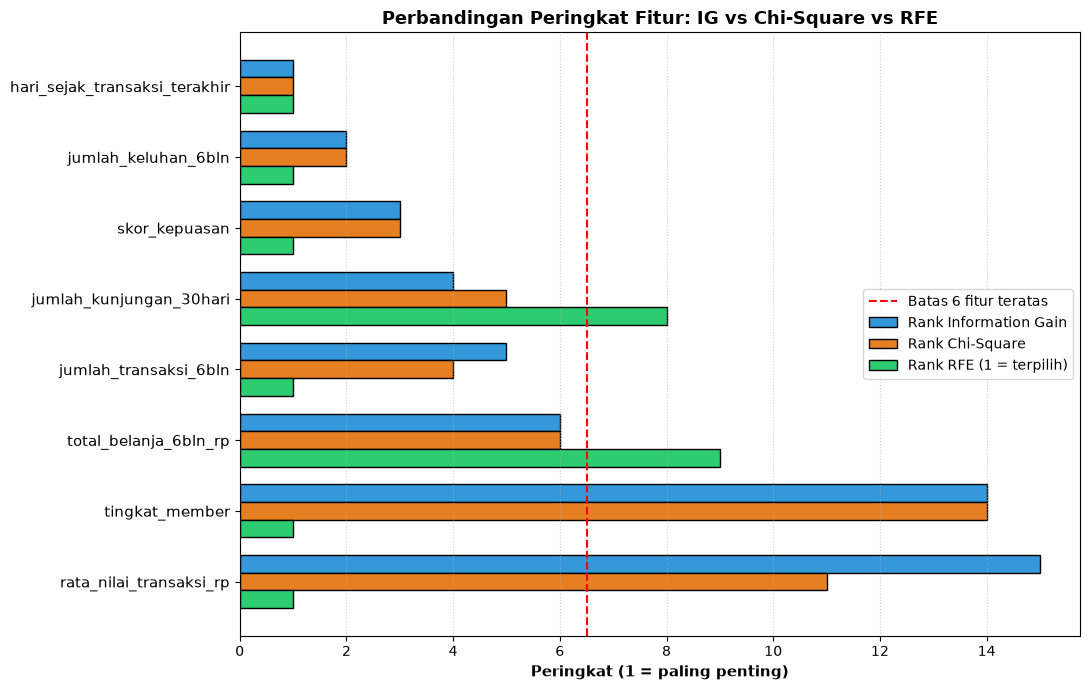

In [5]:
df_top10 = df_komparasi[df_komparasi['Status'] != 'Tidak dipilih'].sort_values(by=['Rank IG']).iloc[::-1]
y_pos = np.arange(len(df_top10))
h = 0.25

plt.figure(figsize=(11, 7))
plt.barh(y_pos + h, df_top10['Rank IG'], height=h, color='#3498db', label='Rank Information Gain', edgecolor='black')
plt.barh(y_pos, df_top10['Rank Chi2'], height=h, color='#e67e22', label='Rank Chi-Square', edgecolor='black')
plt.barh(y_pos - h, df_top10['Rank RFE'], height=h, color='#2ecc71', label='Rank RFE (1 = terpilih)', edgecolor='black')
plt.axvline(x=6.5, color='red', linestyle='--', linewidth=1.5, label='Batas 6 fitur teratas')

plt.yticks(y_pos, df_top10['Nama Fitur'], fontsize=11)
plt.xlabel('Peringkat (1 = paling penting)', fontsize=11, fontweight='bold')
plt.title('Perbandingan Peringkat Fitur: IG vs Chi-Square vs RFE', fontsize=13, fontweight='bold')
plt.legend(loc='center right')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

**Penjelasan:**

- `hari_sejak_transaksi_terakhir`, `jumlah_keluhan_6bln`, `skor_kepuasan`, dan `jumlah_transaksi_6bln` punya batang pendek di ketiga warna, artinya peringkatnya tinggi di semua metode.
- Pada `rata_nilai_transaksi_rp` dan `tingkat_member`, batang hijau (RFE) pendek, tapi batang biru dan oranye (IG dan Chi-Square) panjang. Ini menunjukkan perbedaan paling besar antar metode.
- Pada `jumlah_kunjungan_30hari` dan `total_belanja_6bln_rp` kebalikannya: pendek di IG dan Chi-Square, panjang di RFE.
- Garis merah adalah batas 6 besar. Untuk RFE, semua fitur terpilih punya peringkat 1, jadi batasnya sebenarnya di antara 1 dan 2.

### 6. Benchmark Performa Model

Logistic Regression dilatih dengan 4 kumpulan fitur:
1. Semua fitur (20)
2. 6 fitur Information Gain
3. 6 fitur Chi-Square
4. 6 fitur RFE

Metrik dihitung dengan dua cara:
- **Train**: model dilatih dan dites di data yang sama.
- **CV**: 5-Fold Cross Validation, lebih menggambarkan performa di data baru.

,Skenario,Jumlah Fitur,Akurasi train (%),ROC-AUC train,F1 train,ROC-AUC CV,F1 CV
0,Semua Fitur (20),20,83.6,0.8448,0.5859,0.8281,0.5609
1,Information Gain (6),6,82.4,0.8364,0.5533,0.8316,0.5343
2,Chi-Square (6),6,82.4,0.8364,0.5533,0.8316,0.5343
3,RFE (6),6,82.2,0.8382,0.5459,0.8339,0.5531


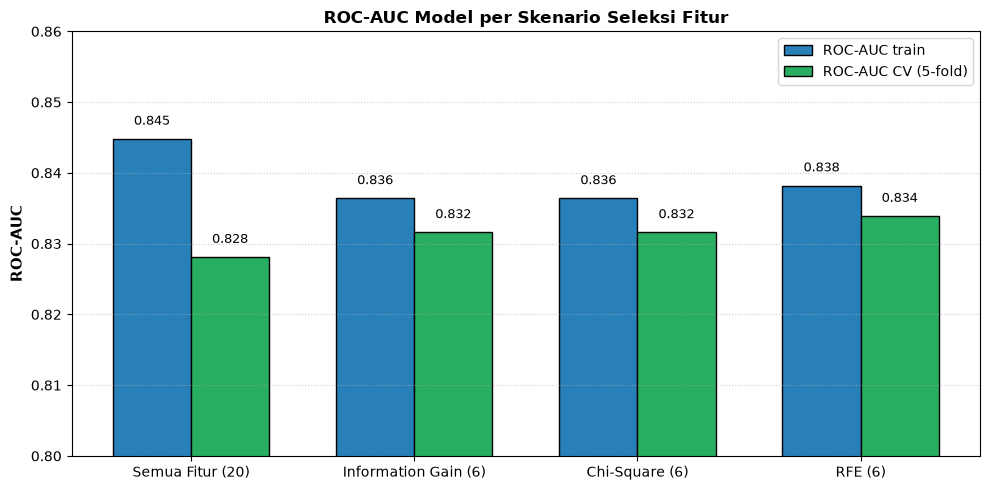

In [6]:
fitur_ig = df_komparasi.sort_values(by='Rank IG')['Nama Fitur'].head(6).tolist()
fitur_chi2 = df_komparasi.sort_values(by='Rank Chi2')['Nama Fitur'].head(6).tolist()
fitur_rfe = df_komparasi[df_komparasi['Terpilih RFE']]['Nama Fitur'].tolist()

skenario = {
    'Semua Fitur (20)': list(X.columns),
    'Information Gain (6)': fitur_ig,
    'Chi-Square (6)': fitur_chi2,
    'RFE (6)': fitur_rfe,
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hasil_bench = []
for nama, cols in skenario.items():
    lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_scaled[cols], y)
    pred = lr.predict(X_scaled[cols])
    prob = lr.predict_proba(X_scaled[cols])[:, 1]
    cv_auc = cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                             X_scaled[cols], y, cv=cv, scoring='roc_auc').mean()
    cv_f1 = cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                            X_scaled[cols], y, cv=cv, scoring='f1').mean()
    hasil_bench.append({
        'Skenario': nama,
        'Jumlah Fitur': len(cols),
        'Akurasi train (%)': round(accuracy_score(y, pred) * 100, 2),
        'ROC-AUC train': round(roc_auc_score(y, prob), 4),
        'F1 train': round(f1_score(y, pred), 4),
        'ROC-AUC CV': round(cv_auc, 4),
        'F1 CV': round(cv_f1, 4),
    })

df_bench = pd.DataFrame(hasil_bench)
display(df_bench)

# Grafik dari hasil di atas
x_pos = np.arange(len(df_bench))
w = 0.35
plt.figure(figsize=(10, 5))
plt.bar(x_pos - w / 2, df_bench['ROC-AUC train'], w, label='ROC-AUC train', color='#2980b9', edgecolor='black')
plt.bar(x_pos + w / 2, df_bench['ROC-AUC CV'], w, label='ROC-AUC CV (5-fold)', color='#27ae60', edgecolor='black')
for i, (a, b) in enumerate(zip(df_bench['ROC-AUC train'], df_bench['ROC-AUC CV'])):
    plt.text(i - w / 2, a + 0.002, f'{a:.3f}', ha='center', fontsize=9)
    plt.text(i + w / 2, b + 0.002, f'{b:.3f}', ha='center', fontsize=9)
plt.xticks(x_pos, df_bench['Skenario'], fontsize=10)
plt.ylabel('ROC-AUC', fontsize=11, fontweight='bold')
plt.title('ROC-AUC Model per Skenario Seleksi Fitur', fontsize=12, fontweight='bold')
plt.ylim(0.80, 0.86)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

**Penjelasan:**

- **Train**: model 20 fitur paling tinggi (akurasi 83,6%, ROC-AUC 0,8448, F1 0,5859). Ini wajar, karena makin banyak fitur, model makin bisa menyesuaikan diri dengan data latihnya.
- **Cross validation**: ketiga model 6 fitur justru punya ROC-AUC lebih tinggi dari model 20 fitur (IG dan Chi-Square 0,8316, RFE 0,8339, sedangkan 20 fitur 0,8281). Artinya 14 fitur yang dibuang tidak membantu prediksi di data baru.
- Hasil IG dan Chi-Square sama persis karena 6 fitur yang dipilih memang sama.
- F1-Score semua model masih rendah (sekitar 0,53-0,56). Penyebabnya kelas churn hanya 24%, dan model memakai threshold default 0,5, sehingga banyak pelanggan churn yang tidak terdeteksi. Ini bisa diperbaiki dengan `class_weight='balanced'` atau dengan menurunkan threshold, tapi itu di luar topik seleksi fitur.
- Selisih ROC-AUC antar skenario di CV sangat kecil (di bawah 0,006), jadi performa keempat skenario bisa dibilang setara. Keuntungan utama seleksi fitur di sini adalah model jadi lebih sederhana (6 fitur, bukan 20) tanpa kehilangan performa.

### 7. Simpan Tabel Perbandingan

Tabel perbandingan disimpan ke `Matriks_Perbandingan_Feature_Selection.csv`.

In [7]:
df_komparasi.to_csv('Matriks_Perbandingan_Feature_Selection.csv', index=False)
print(f"Tabel perbandingan disimpan ke 'Matriks_Perbandingan_Feature_Selection.csv' ({df_komparasi.shape[0]} baris, {df_komparasi.shape[1]} kolom).")

Tabel perbandingan disimpan ke 'Matriks_Perbandingan_Feature_Selection.csv' (20 baris, 9 kolom).


**Penjelasan:**

File CSV berisi 20 baris (satu per fitur) dengan skor IG, skor dan p-value Chi-Square, peringkat ketiga metode, dan status pemilihannya. File ini bisa dipakai untuk dokumentasi atau dibuka lagi tanpa harus menjalankan ulang semua perhitungan.

### 8. Kesimpulan

- Ketiga metode sepakat pada 4 fitur utama: `hari_sejak_transaksi_terakhir`, `jumlah_keluhan_6bln`, `skor_kepuasan`, dan `jumlah_transaksi_6bln`.
- IG dan Chi-Square memberi hasil yang hampir sama. RFE berbeda di 2 fitur terakhir, dan perbedaannya lebih karena outlier dan cara encoding, bukan karena RFE menemukan pola baru.
- Memakai 6 fitur saja tidak menurunkan performa dibanding 20 fitur. Di cross validation, ROC-AUC-nya malah sedikit lebih tinggi.

Kapan pakai metode yang mana:
- **Information Gain**: untuk eksplorasi awal, cepat, dan tidak butuh preprocessing. Cocok juga kalau model akhirnya berbasis pohon (Decision Tree, Random Forest), karena cara kerjanya mirip.
- **Chi-Square**: kalau butuh dasar statistik (p-value), atau kalau sebagian besar fiturnya kategorikal.
- **RFE**: kalau tujuannya mencari kombinasi fitur terbaik untuk model tertentu. Tapi hasilnya sangat bergantung pada preprocessing, jadi outlier dan encoding harus ditangani dengan benar dulu.